### Data Analysis

##### Database Analysis

Ziel: Prozentualer Anteil der Klassen bestimmen (Problem Klassen die ineinander liegen)

heutiges Ziel: Anzahl der Klassen

Cheat Sheet: https://www.w3schools.com/sql/sql_groupby.asp

In [1]:
#Imports 
import sqlite3
import pandas as pd
from pandasql import sqldf
from sklearn import datasets

In [2]:
#open db as sqlite 
db = sqlite3.connect('/home/klose/Data/CMC-21 Klassen-ROI.sqlite')
#open Annotations Table
df = pd.read_sql("select * from Annotations", db)


In [3]:
#get first rows of df 
print(df.head(2))

   uid  slide                                  guid  lastModified  deleted  \
0    1      1  6d9db2a9-ee75-427d-9e92-57cb46078a36  1.664371e+09        0   
1    2      1  33e46de8-7c8f-4c83-a9e9-554a32298ef6  1.664371e+09        0   

   type  agreedClass description  clickable  
0     2           21                      1  
1     3            2                      1  


In [4]:
type(df)

pandas.core.frame.DataFrame

In [5]:
#joinen der Klassenids mit Klassennamen 
df_namen = pd.read_sql("select uid, name from Classes", db)
df_namen.head(2)

,uid,name
0,1,Lumen
1,2,Tumor


In [6]:
df_mit_namen = sqldf("SELECT * from df INNER JOIN df_namen ON df.agreedClass=df_namen.uid")
df_mit_namen.head(2)

,uid,slide,guid,lastModified,deleted,type,agreedClass,description,clickable,uid,name
0,1,1,6d9db2a9-ee75-427d-9e92-57cb46078a36,1.664371e+09,0,2,21,,1,21,Annotationskasten
1,2,1,33e46de8-7c8f-4c83-a9e9-554a32298ef6,1.664371e+09,0,3,2,,1,2,Tumor


In [7]:
#WIe häufig kommen die einzelnen Klassen vor 
#Klassenhäufigkeit in jedem Slide 
df_anzahl_klassen_perslide = sqldf("select slide, name, '1' AS Anzahl FROM df_mit_namen GROUP BY slide, agreedClass ORDER BY slide, agreedClass")
df_anzahl_klassen_perslide

,slide,name,Anzahl
0,1,Tumor,1
1,1,Solid - Pleo 2,1
2,1,Normal,1
3,1,Tumorstroma,1
4,1,Annotationskasten,1
...,...,...,...
801,116,Solid - Pleo 2,1
802,116,Solid - Pleo 3,1
803,116,Nekrose / Entzündung,1
804,116,Tumorstroma,1


In [8]:
#Klassenhäufigkeit in allen Slides 
df_anzahl_klassen = sqldf("SELECT name, count(Anzahl) AS Anzahl FROM df_anzahl_klassen_perslide GROUP BY name")
df_anzahl_klassen 

,name,Anzahl
0,Annotationskasten,116
1,Gefäße - Frei,72
2,Gefäße - Metastase,18
3,Ignore,10
4,Lumen,7
5,Micropap. P2,1
6,Nekrose / Entzündung,94
7,Normal,39
8,Solid - Pleo 1,49
9,Solid - Pleo 2,75


<AxesSubplot: xlabel='name'>

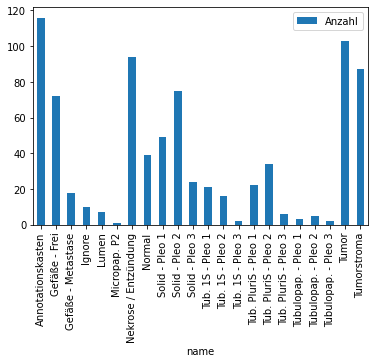

In [9]:
#Visualisieren 
df_anzahl_klassen.plot(kind = 'bar', x = 'name', y='Anzahl')

### Train, Test, Valid Database Verteilung analysieren

In [10]:
data = pd.read_csv("/home/klose/Data/datasets.csv", delimiter=";")
df_csv = pd.DataFrame(data)

In [21]:
#csv Datei mit Slide und Dataset 
df_csv

,Slide,Dataset
0,CP_CMC_19_133 D.svs_2.tiff,train
1,CP_CMC_16_2653 C.svs_1.tiff,train
2,CP_CMC_21_1431 B.svs_1.tiff,train
3,CP_CMC_18_6735 1C.svs_2.tiff,train
4,CP_CMC_22_40.svs_1.tiff,train
...,...,...
112,CP_CMC_22_8168.svs_1.tiff,test
113,CP_CMC_17_5641 F.svs_2.tiff,test
114,CP_CMC_19_3271 A.svs_2.tiff,test
115,CP_CMC_18_3906 D.svs_1.tiff,test


In [22]:
#df mit namen und ids df = pd.read_sql("select * from Annotations", db)
df_name_id = pd.read_sql("select uid, filename from slides", db)
df_name_id.head(2)

,uid,filename
0,1,CP_CMC_22_3041 A.svs_1.tiff
1,2,CP_CMC_22_2591 1.svs_1.tiff


In [24]:
#joinen der slidenamen und ids mit csv 
df_dataset = sqldf("select Slide as name_slide, Dataset, uid, filename from df_csv INNER JOIN df_name_id ON df_name_id.filename = df_csv.Slide ORDER BY uid")
df_dataset.shape

(116, 4)

In [27]:
#joinen des Datasets mit df_anzahl_klassen_perslide
df_anzahl_klassen_perslide_dataset = sqldf("SELECT * from df_anzahl_klassen_perslide INNER JOIN df_dataset ON df_anzahl_klassen_perslide.slide = df_dataset.uid")
df_anzahl_klassen_perslide_dataset

,slide,name,Anzahl,name_slide,Dataset,uid,filename
0,1,Tumor,1,CP_CMC_22_3041 A.svs_1.tiff,val,1,CP_CMC_22_3041 A.svs_1.tiff
1,1,Solid - Pleo 2,1,CP_CMC_22_3041 A.svs_1.tiff,val,1,CP_CMC_22_3041 A.svs_1.tiff
2,1,Normal,1,CP_CMC_22_3041 A.svs_1.tiff,val,1,CP_CMC_22_3041 A.svs_1.tiff
3,1,Tumorstroma,1,CP_CMC_22_3041 A.svs_1.tiff,val,1,CP_CMC_22_3041 A.svs_1.tiff
4,1,Annotationskasten,1,CP_CMC_22_3041 A.svs_1.tiff,val,1,CP_CMC_22_3041 A.svs_1.tiff
...,...,...,...,...,...,...,...
801,116,Solid - Pleo 2,1,CP_CMC_22_29.svs_1.tiff,train,116,CP_CMC_22_29.svs_1.tiff
802,116,Solid - Pleo 3,1,CP_CMC_22_29.svs_1.tiff,train,116,CP_CMC_22_29.svs_1.tiff
803,116,Nekrose / Entzündung,1,CP_CMC_22_29.svs_1.tiff,train,116,CP_CMC_22_29.svs_1.tiff
804,116,Tumorstroma,1,CP_CMC_22_29.svs_1.tiff,train,116,CP_CMC_22_29.svs_1.tiff


In [ ]:
#besseren Split erstellen - mit Tumor und Normal gleichmäßig verteilt 


In [52]:
#wichtiges filtern 
df_anzahl_klassen = sqldf("SELECT slide, name, Anzahl, Dataset, filename FROM df_anzahl_klassen_perslide_dataset")
#Klassenhäufigkeit in allen Slides 
print(df_anzahl_klassen.shape)
print(df_anzahl_klassen)

#verteliung ausgeben 
df_verteilung_klassen = sqldf("SELECT count(distinct(Slide)) as Anzahl_Slides, Dataset FROM df_anzahl_klassen GROUP BY Dataset")
print(df_verteilung_klassen, '\n')

#Klassenhäufigkeit in allen Slides zusammenrechnen
df_anzahl_klassen = sqldf("SELECT name, count(Anzahl) AS Anzahl, Dataset  FROM df_anzahl_klassen GROUP BY Dataset, name")
print(df_anzahl_klassen) 
print(df_anzahl_klassen.shape)
# df_anzahl_klassen = sqldf("SELECT name, count(Anzahl) AS Anzahl, Dataset FROM df_anzahl_klassen GROUP BY name")
# df_anzahl_klassen.head(2)

(806, 5)
     slide                  name Anzahl Dataset                     filename
0        1                 Tumor      1     val  CP_CMC_22_3041 A.svs_1.tiff
1        1        Solid - Pleo 2      1     val  CP_CMC_22_3041 A.svs_1.tiff
2        1                Normal      1     val  CP_CMC_22_3041 A.svs_1.tiff
3        1           Tumorstroma      1     val  CP_CMC_22_3041 A.svs_1.tiff
4        1     Annotationskasten      1     val  CP_CMC_22_3041 A.svs_1.tiff
..     ...                   ...    ...     ...                          ...
801    116        Solid - Pleo 2      1   train      CP_CMC_22_29.svs_1.tiff
802    116        Solid - Pleo 3      1   train      CP_CMC_22_29.svs_1.tiff
803    116  Nekrose / Entzündung      1   train      CP_CMC_22_29.svs_1.tiff
804    116           Tumorstroma      1   train      CP_CMC_22_29.svs_1.tiff
805    116     Annotationskasten      1   train      CP_CMC_22_29.svs_1.tiff

[806 rows x 5 columns]
   Anzahl_Slides Dataset
0             12  

In [53]:
#Datasets in die Gruppen einteilen und visualisieren 
df_train = sqldf("SELECT * FROM df_anzahl_klassen WHERE Dataset == 'train'")
df_val = sqldf("SELECT * FROM df_anzahl_klassen WHERE Dataset == 'val'")
#test ist nicht enthalten !
df_test = sqldf("SELECT * FROM df_anzahl_klassen WHERE Dataset == 'test'")

<AxesSubplot: xlabel='name'>

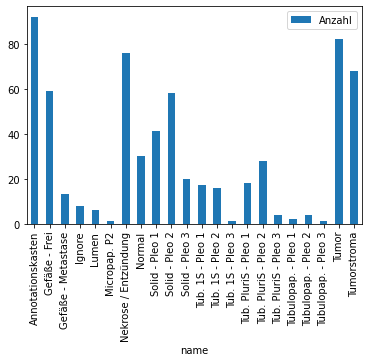

In [54]:
#train 
df_train.plot(kind = 'bar', x = 'name', y='Anzahl')

<AxesSubplot: xlabel='name'>

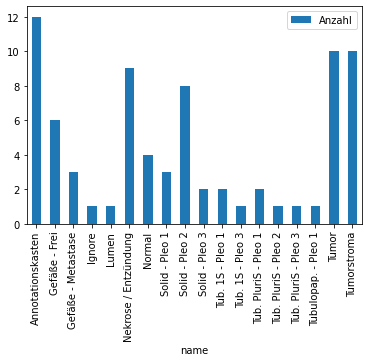

In [55]:
#val
df_val.plot(kind = 'bar', x = 'name', y='Anzahl')

<AxesSubplot: xlabel='name'>

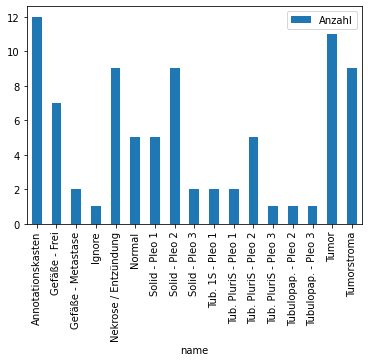

In [56]:
#test
df_test.plot(kind = 'bar', x = 'name', y='Anzahl')

#### Image Analysis

In [11]:
# openslide importieren
import openslide
import matplotlib.pyplot as plt

In [4]:
# Slide file
img_file = '/home/klose/Data/crops/CP_CMC_16_954 B.svs_1.tiff'
# Slide öffnen
slide = openslide.open_slide(img_file)


In [5]:
# Slide Größe
print(f"Anzahl an Pixeln in x Richtung: {slide.dimensions[0]}, Anzahl an Pixeln in y Richtung: {slide.dimensions[1]}")
# Anzahl an Pyramiden Level
print(f"Anzahl an Pyramiden Leveln: {slide.level_count}")
# Downsampling Faktor pro Pyramidenstufe im Verhältnis zur am höchsten aufgelösten Stufe
print(f'Downsampling Factors: {slide.level_downsamples}')
# Größe des Slide auf den verschiedenen Leveln
print(f"Größe des Slides auf den verschidenen Leveln: {slide.level_dimensions}")

Anzahl an Pixeln in x Richtung: 4198, Anzahl an Pixeln in y Richtung: 2262
Anzahl an Pyramiden Leveln: 1
Downsampling Factors: (1.0,)
Größe des Slides auf den verschidenen Leveln: ((4198, 2262),)


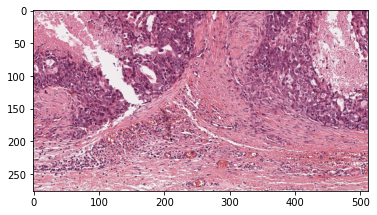

In [6]:
# Größe des thumbnails
size = (512,512)

thumbnail = slide.get_thumbnail(size=size)
plt.imshow(thumbnail)

### Pytorch Dataloader, because we cannnot load the full image 

In [7]:
import torch 

from torch.utils.data import Dataset
from numpy.random import randint, choice


class MyCustomDataset(Dataset):
    def __init__(self, slide_list:list, crop_size:int, slide_path:str, pseudo_epoch_lengh:int = 100) -> None:
        super().__init__()
        
        self.slide_list = slide_list
        self.crop_size = crop_size
        self.slide_path = slide_path
        self.pseudo_epoch_length = pseudo_epoch_lengh

        self.slide_objects = self.__inititalize__(slide_list,slide_path)

    def __inititalize__(self, slide_list, slide_path):
        return [openslide.open_slide(slide_path + slide) for slide in slide_list]

    def __len__(self):
        return self.pseudo_epoch_length

    def __getitem__(self, index):
        # Slide aus einer Liste an Slides aussuchen
        slide = choice(self.slide_objects,1)[0]
        # Zufällig Koordinaten ziehen
        width,height = slide.dimensions
        x,y = randint((0,0),(width - self.crop_size, height - self.crop_size),(2,))
        # Region auslesen
        crop = slide.read_region((x,y),0,(self.crop_size,self.crop_size))

        return crop

ValueError: high <= 0

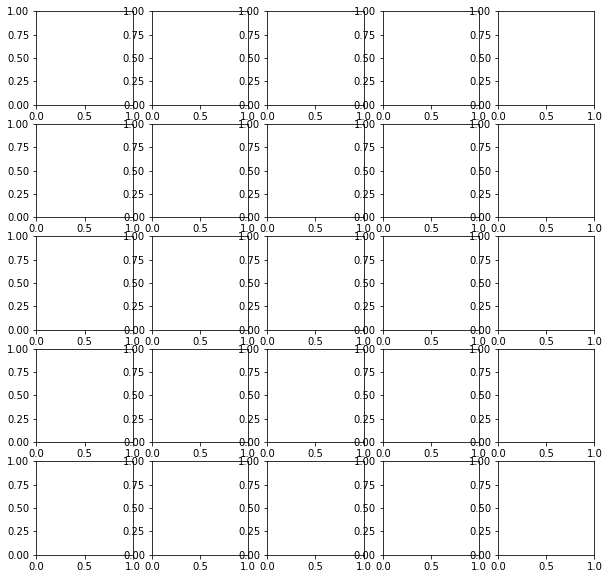

In [9]:
ds = MyCustomDataset(slide_list=[img_file],crop_size = 5000,slide_path = '')

fig,ax = plt.subplots(5,5,figsize = (10,10))
ax = ax.flatten()

for i,a in enumerate(ax):
    a.imshow(ds[i])
    a.axis('off')

plt.tight_layout()

#### Slide Container von Frauke Wilm 

In [1]:
import sys 
sys.path.insert(0, '..')
from fastai.utils.collect_env import show_install
from evaluation.metrics import *
from fastai.callbacks.tracker import SaveModelCallback
from slide.slide_helper import SlideSegmentationItemList, SlideSegmentationLabelList
from slide.process_slides import *
from torchsummary import summary
# from custom_loss_functions import ComboLoss
# from custom_callbacks import UpdateProbabilitiesCallback
from torchvision import transforms

In [2]:
#Model INput Parameters 
patch_size = 512
patches_per_slide = 5 #10 # define number of pathes sampled per slide for each pseudo-epoch
batch_size = 6 #8
level = 0 # resolution level of image pyramid (higher level corresponds to lower resoution)
lr = 1e-4
encoder = models.resnet18

In [3]:
target_folder = "/home/klose/Data/crops"
annotation_file = "/home/klose/Data/CMC.json"

In [4]:
#mein eigenes 
#Label Dict, -1 is not relevant 
label_dict = {'Bg':0 , 'Lumen': -1, 'Tumor': 1, 'Normal': 2,
              'Tub. 1S - Pleo 1': -1, 'Tub. 1S - Pleo 2': -1, 'Tub. 1S - Pleo 3': -1, 
              'Tub. PluriS - Pleo 1': -1, 'Tub. PluriS - Pleo 2': -1, 'Tub. PluriS - Pleo 3':-1,
             'Tubulopap. - Pleo 1': -1, 'Tubulopap. - Pleo 2': -1, 'Tubulopap. - Pleo 3': -1, 
            'Solid - Pleo 1': -1, 'Solid - Pleo 2': -1, 'Solid - Pleo 3': -1,
             'Nekrose / Entzündung': -1,  'Gefäße - Frei': -1, 'Gefäße - Metastase': -1,
             'Tumorstroma': -1, 'Ignore': -1, 'Annotationskasten': -1,
             'Micropap. P1': -1, 'Micropap. P2': -1, 'Micropap. P3': -1,
             'Kasten - vereinfacht': -1, 'Kasten - Test': -1, 
              'A1 - B1': -1,'A1 - B2': -1, 'A1 - B3': -1, 'A2 - B1': -1,'A2 - B2': -1,'A2 - B3':-1, 'A3 - B1':-1, 'A3 - B2':-1,'A3 - B3':-1}

In [5]:
#load files
train_files, valid_files, _ = load_slides(["train","valid"], patch_size,label_dict, level, target_folder, annotation_file = annotation_file, dataset_type='segmentation')
train_data = create_patches(train_files, patches_per_slide)
valid_data = create_patches(valid_files, patches_per_slide)

100%|██████████| 115/115 [00:15<00:00,  7.58it/s]


In [9]:
print(train_data[0])

[<slide.slide_container.SlideContainer object at 0x7f089c96a760>, <slide.slide_container.SlideContainer object at 0x7f089c3ef850>, <slide.slide_container.SlideContainer object at 0x7f0890c90d00>, <slide.slide_container.SlideContainer object at 0x7f089c2cffa0>, <slide.slide_container.SlideContainer object at 0x7f089c96ab50>, <slide.slide_container.SlideContainer object at 0x7f089cb5bf10>, <slide.slide_container.SlideContainer object at 0x7f0890f67b50>, <slide.slide_container.SlideContainer object at 0x7f089c2af370>, <slide.slide_container.SlideContainer object at 0x7f0890c903d0>, <slide.slide_container.SlideContainer object at 0x7f089c96acd0>, <slide.slide_container.SlideContainer object at 0x7f089c316100>, <slide.slide_container.SlideContainer object at 0x7f089cb5bf10>, <slide.slide_container.SlideContainer object at 0x7f0890955d90>, <slide.slide_container.SlideContainer object at 0x7f0890e23370>, <slide.slide_container.SlideContainer object at 0x7f0890cb4430>, <slide.slide_container.S

In [16]:
#print(train_data)

for i,a in enumerate(train_data):
    a.imshow(ds[i])
    a.axis('off')

plt.tight_layout()

AttributeError: 'SlideContainer' object has no attribute 'imshow'

In [10]:
#use transformations
tfms = get_transforms(do_flip=True,
                      flip_vert=True,
                      max_rotate=45,
                      max_lighting=0.15,
                      max_zoom=0)

In [6]:
def get_y_func(x):
    return x

In [7]:
#create Data bunch 
train = SlideSegmentationItemList(train_data)
valid = SlideSegmentationItemList(valid_data)
path = Path('.')
item_list = ItemLists(path, train, valid)
item_list = item_list.label_from_func(get_y_func, classes=['Bg', 'Tumor', 'Normal'],label_cls=SlideSegmentationLabelList)

In [11]:
#normalize with training set statistics 
data = item_list.transform(tfms, size=patch_size, tfm_y=True).databunch(bs=batch_size, no_check=True, num_workers=0).normalize(([0.7587, 0.5718, 0.6572],[0.0866, 0.1118, 0.0990])) # For Windows num_workers has to be set to 0

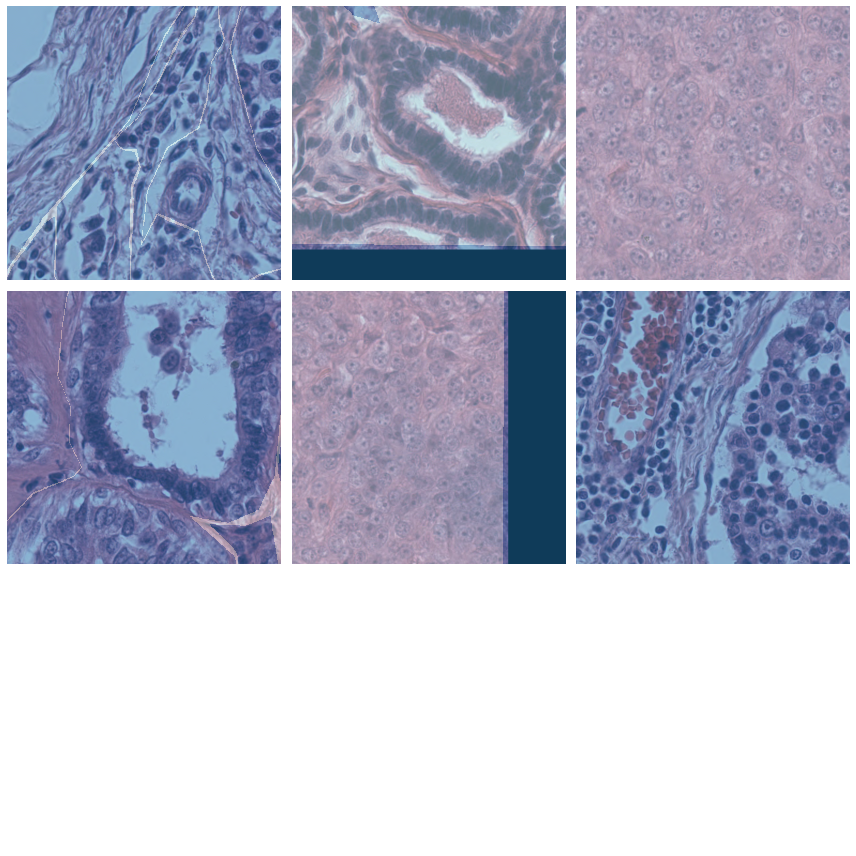

In [12]:
data.show_batch(ds_type=DatasetType.Valid)